For binary ischemic / non-ischemic labels we used the reference implementation contained in the `labels_binary_classification.py` utility module to ensure full consistency with the official labeling procedure.


In [2]:
import sys
import os
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), "../.."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)
import pandas as pd
from src.utils.labels_binary_classification import generate_ischemic_labels
PROFILE_PATH = "../../data/processed/patient_profile.csv"
DIAG_PATH = "../../data/raw/heart_diagnoses_1.csv"
LABELS_OUT = "../../data/processed/subject_to_labels_ischemic.csv"
df = pd.read_csv(PROFILE_PATH)
df["subject_id"] = df["subject_id"].astype(str)

print("Patient profile loaded:", df.shape)

labels_df = generate_ischemic_labels(
    diagnoses_path=DIAG_PATH,
    output_path=LABELS_OUT
)

print("Labels generated:")
print(labels_df["label_ischemic"].value_counts())

clf_df = df.merge(labels_df, on="subject_id", how="inner")

# Remove ICD-derived features to avoid data leakage
ICD_MACRO_COLS = [
    "ACS_acute_ischemic",
    "Chronic_ischemic",
    "Heart_failure",
    "Valvular_nonrheumatic",
    "Myocarditis_or_cardiomyopathy",
    "Pericardial_disease",
    "Endocarditis",
    "Cardiac_arrest",
    "Arrhythmias_or_conduction",
]

clf_df = clf_df.drop(columns=[c for c in ICD_MACRO_COLS if c in clf_df.columns])

print("Final classification dataset:", clf_df.shape)
clf_df


Patient profile loaded: (4384, 36)
Labels generated:
label_ischemic
0    2374
1    2018
Name: count, dtype: int64
Final classification dataset: (4384, 28)


,subject_id,number_of_hadm,gender,age,lab_event_count,microbio_test_count,unique_microorganisms_count,unique_antibiotics_count,unique_procedures_count,max_glucose,...,max_ptt,max_inr(pt),max_hemoglobin,max_platelet count,max_white blood cells,max_cholesterol ratio (total/hdl),min_ph,max_pco2,abnormal_lab_event_ratio,label_ischemic
0,10000980,2,1,75,169.0,1.0,0.0,0.0,7.0,3.100000,...,5.286957,2.0,-0.475000,0.251724,0.328571,1.000000,0.0,0.0,0.408284,1
1,10002013,1,1,69,40.0,0.0,0.0,0.0,2.0,10.833333,...,4.634783,0.5,0.025000,0.389655,0.714286,0.000000,0.0,0.0,0.375000,1
2,10002155,1,1,69,287.0,4.0,0.0,0.0,8.0,2.000000,...,5.661538,10.5,0.125000,0.341379,0.500000,0.000000,0.8,1.3,0.386760,1
3,10004457,1,0,66,21.0,0.0,0.0,0.0,0.0,0.733333,...,0.000000,0.0,-0.075000,0.396552,0.357143,1.228571,0.0,0.0,0.333333,0
4,10007058,1,0,48,112.0,2.0,0.0,0.0,2.0,1.366667,...,4.582609,1.5,-0.315789,0.220000,1.416667,0.742857,0.0,0.0,0.375000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4379,19998596,1,1,71,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0
4380,19998597,1,1,57,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0
4381,19998598,1,1,69,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0
4382,19998599,1,0,59,0.0,0.0,0.0,0.0,0.0,0.000000,...,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0


Although the dataset is only mildly imbalanced, balanced accuracy and ROC-AUC were included to ensure robustness and comparability across models.


## Logistic Regression
In this section, firstly we trained a Logistic Regression model as a baseline, estimating $P(y=1\mid x)$ via the sigmoid function and a decision threshold.

In [3]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    RocCurveDisplay
)


In [ ]:
# Train/Test split (stratified)
TARGET = "label_ischemic"
ID_COL = "subject_id"

X = clf_df.drop(columns=[TARGET, ID_COL])
y = clf_df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30, #70% training, 30% test
    stratify=y,
    random_state=42
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train label distribution:\n", y_train.value_counts(normalize=True))
print("Test  label distribution:\n", y_test.value_counts(normalize=True))


Train: (3068, 26)  Test: (1316, 26)
Train label distribution:
 label_ischemic
0    0.539765
1    0.460235
Name: proportion, dtype: float64
Test  label distribution:
 label_ischemic
0    0.539514
1    0.460486
Name: proportion, dtype: float64


The distribution is practically identical between train and test sets, confirming that the stratified split worked correctly. The dataset already satisfies the assumptions of Logistic Regression. All features are numerical, scaled, free from label leakage, and missing values were handled during data preparation. Therefore, no additional preprocessing steps were required for the baseline model.

In [ ]:

lr_clf = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        penalty="l2",          
        C=1.0,               
        solver="lbfgs",
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

lr_clf.fit(X_train, y_train)


,steps,"[('scaler', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,copy,True
,with_mean,True
,with_std,True
,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0


In [ ]:
# Evaluation: train vs test

def evaluate_binary(model, Xtr, ytr, Xte, yte):
    # predictions (0/1)
    ytr_pred = model.predict(Xtr)
    yte_pred = model.predict(Xte)

    # probability
    ytr_proba = model.predict_proba(Xtr)[:, 1]
    yte_proba = model.predict_proba(Xte)[:, 1]

    results = {
        "train_accuracy": accuracy_score(ytr, ytr_pred),
        "test_accuracy": accuracy_score(yte, yte_pred),
        "train_balanced_accuracy": balanced_accuracy_score(ytr, ytr_pred),
        "test_balanced_accuracy": balanced_accuracy_score(yte, yte_pred),
        "train_precision": precision_score(ytr, ytr_pred),
        "test_precision": precision_score(yte, yte_pred),
        "train_recall": recall_score(ytr, ytr_pred),
        "test_recall": recall_score(yte, yte_pred),
        "train_f1": f1_score(ytr, ytr_pred),
        "test_f1": f1_score(yte, yte_pred),
        "train_roc_auc": roc_auc_score(ytr, ytr_proba),
        "test_roc_auc": roc_auc_score(yte, yte_proba),
    }
    return results, (ytr_pred, yte_pred, ytr_proba, yte_proba)

lr_results, (y_train_pred, y_test_pred, y_train_proba, y_test_proba) = evaluate_binary(
    lr_clf, X_train, y_train, X_test, y_test
)

pd.Series(lr_results).sort_index()


test_accuracy              0.819149
test_balanced_accuracy     0.816200
test_f1                    0.798646
test_precision             0.819444
test_recall                0.778878
test_roc_auc               0.906233
train_accuracy             0.812907
train_balanced_accuracy    0.809525
train_f1                   0.790511
train_precision            0.815512
train_recall               0.766997
train_roc_auc              0.898275
dtype: float64

No overfitting observed. The Logistic Regression baseline shows strong and well-balanced performance. Train and test metrics are very similar, indicating good generalization and no evidence of overfitting. In particular, the ROC-AUC above 0.9 suggests that the model is highly effective at ranking ischemic patients ahead of non-ischemic ones.

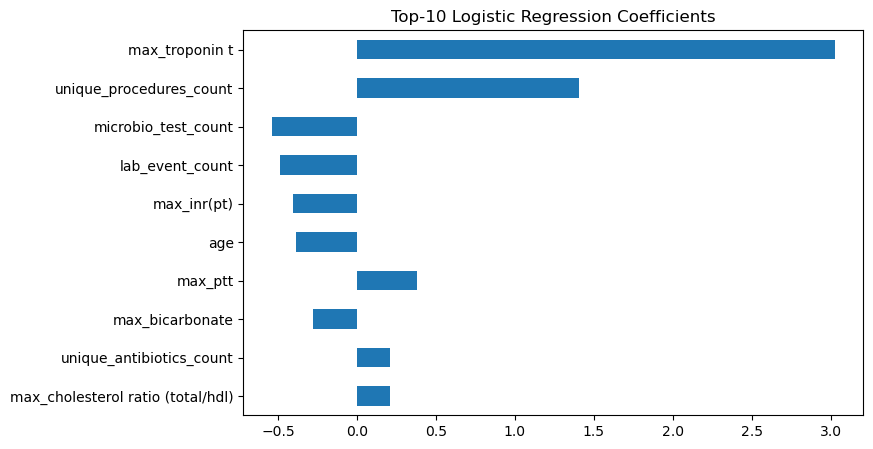

In [7]:
coef = lr_clf.named_steps["model"].coef_[0]
coef_df = (
    pd.Series(coef, index=X.columns)
    .sort_values(key=np.abs, ascending=False)
)

coef_df.head(10)
plt.figure(figsize=(8, 5))
coef_df.head(10).plot(kind="barh")
plt.title("Top-10 Logistic Regression Coefficients")
plt.gca().invert_yaxis()
plt.show()



The analysis of the Logistic Regression coefficients provides insight into the interpretability of the baseline model.
Since all features were standardized, the magnitude of each coefficient reflects its relative contribution to the log-odds of ischemia.

The strongest positive coefficient is associated with maximum troponin levels, which is clinically consistent with ischemic events.
Other positively weighted features capture patient complexity and coagulation abnormalities.
Negative coefficients suggest variables that, conditionally on the others, are more frequently associated with non-ischemic patients.

This analysis confirms that the Logistic Regression model is not only predictive but also clinically interpretable.


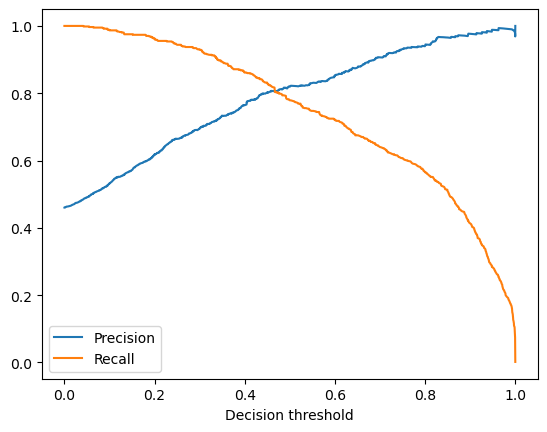

In [8]:
from sklearn.metrics import precision_recall_curve

prec, rec, thr = precision_recall_curve(y_test, y_test_proba)

plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.xlabel("Decision threshold")
plt.legend()
plt.show()


The Precision–Recall vs decision threshold curve highlights the trade-off induced by the choice of the classification threshold.
Lower thresholds lead to higher recall at the expense of precision, while higher thresholds improve precision but significantly reduce recall.

This analysis shows that the default threshold of 0.5 represents a balanced compromise, but alternative thresholds could be selected depending on the clinical objective, for instance prioritizing recall to minimize false negatives in ischemic patients.


In [9]:
from sklearn.model_selection import cross_val_score

cv_scores_lr = cross_val_score(
    lr_clf,
    X_train,
    y_train,
    cv=5,
    scoring="balanced_accuracy"
)

print("Logistic Regression - 5-fold CV balanced accuracy")
print(f"Mean = {cv_scores_lr.mean():.3f}")
print(f"Std  = {cv_scores_lr.std():.3f}")


Logistic Regression - 5-fold CV balanced accuracy
Mean = 0.806
Std  = 0.012


To further assess the robustness of the Logistic Regression model, we evaluated its
performance using 5-fold cross-validation on the training set.

The mean balanced accuracy across folds is 0.81, which is fully consistent with the
performance observed on the held-out test set.
The very low standard deviation (0.012) indicates that the model is stable and that
its performance does not depend on a particular data split.

This result confirms that Logistic Regression provides a reliable and well-generalizing
baseline for the ischemic vs non-ischemic classification task.


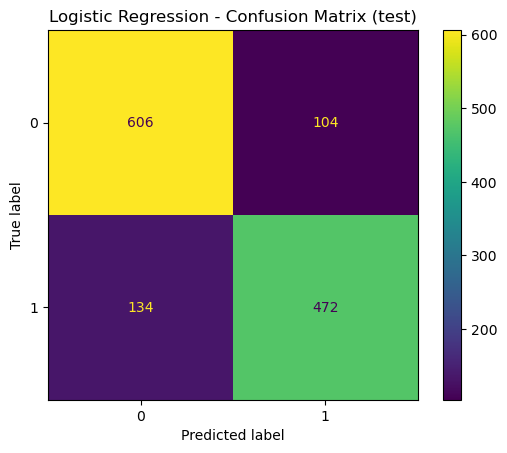


Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.82      0.85      0.84       710
    Ischemic (1)       0.82      0.78      0.80       606

        accuracy                           0.82      1316
       macro avg       0.82      0.82      0.82      1316
    weighted avg       0.82      0.82      0.82      1316



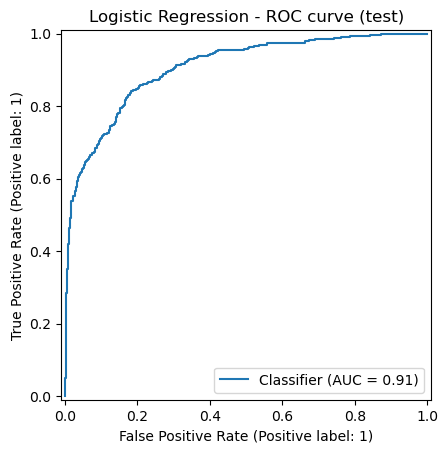

In [ ]:
# Confusion matrix (test)
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot()
plt.title("Logistic Regression - Confusion Matrix (test)")
plt.show()

print("\nClassification report (test):")
print(classification_report(y_test, y_test_pred, target_names=["Non-ischemic (0)", "Ischemic (1)"]))

# ROC curve (test)
RocCurveDisplay.from_predictions(y_test, y_test_proba)
plt.title("Logistic Regression - ROC curve (test)")
plt.show()


We first trained a Logistic Regression model as a baseline classifier for the ischemic vs non-ischemic task.
The model was trained using L2 regularization and class-balanced loss. Feature standardization was applied to ensure numerical stability and interpretability of the learned coefficients.

On the test set, the model achieved an accuracy of 0.82 and a balanced accuracy of 0.82, indicating consistent performance across both classes.
The ROC-AUC score of 0.91 highlights a strong discriminative ability, suggesting that ischemic and non-ischemic patients are well separated in the feature space.

The confusion matrix shows a moderate number of false negatives, reflecting a trade-off between precision and recall that is typical in clinical classification tasks.
Overall, Logistic Regression provides a solid and interpretable baseline for further comparison with more complex models.

## Naive Bayes Classifier

We trained a Gaussian Naive Bayes classifier as a second baseline model.
Naive Bayes is a generative probabilistic classifier that estimates class-conditional feature distributions under the assumption of conditional independence.
Despite its strong assumptions, it is often competitive in high-dimensional clinical datasets and provides a useful comparison to discriminative models such as Logistic Regression.


In [11]:
from sklearn.naive_bayes import GaussianNB

Scaling is not required for Gaussian Naive Bayes, since each feature distribution is modeled independently through its own mean and variance.

In [12]:
# Naive Bayes (Gaussian)
nb_clf = GaussianNB()

nb_clf.fit(X_train, y_train)


,priors,None
,var_smoothing,1e-09


In [13]:
nb_results, (nb_y_train_pred, nb_y_test_pred,
             nb_y_train_proba, nb_y_test_proba) = evaluate_binary(
    nb_clf, X_train, y_train, X_test, y_test
)

pd.Series(nb_results).sort_index()

test_accuracy              0.794073
test_balanced_accuracy     0.782808
test_f1                    0.741165
test_precision             0.879819
test_recall                0.640264
test_roc_auc               0.880607
train_accuracy             0.776076
train_balanced_accuracy    0.765337
train_f1                   0.721524
train_precision            0.843602
train_recall               0.630312
train_roc_auc              0.856371
dtype: float64

Naive Bayes shows good ranking ability (ROC-AUC), but suboptimal recall due to its strong independence assumption.

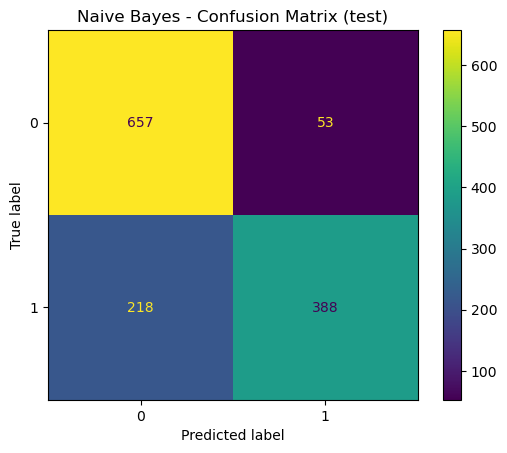


Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.75      0.93      0.83       710
    Ischemic (1)       0.88      0.64      0.74       606

        accuracy                           0.79      1316
       macro avg       0.82      0.78      0.79      1316
    weighted avg       0.81      0.79      0.79      1316



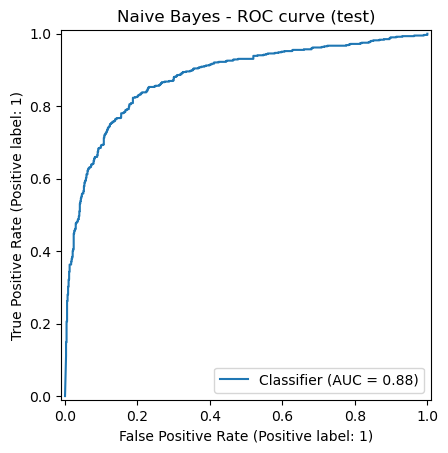

In [14]:
# Confusion matrix (test)
cm_nb = confusion_matrix(y_test, nb_y_test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_nb, display_labels=[0, 1])
disp.plot()
plt.title("Naive Bayes - Confusion Matrix (test)")
plt.show()

print("\nClassification report (test):")
print(classification_report(
    y_test, nb_y_test_pred,
    target_names=["Non-ischemic (0)", "Ischemic (1)"]
))

# ROC curve (test)
RocCurveDisplay.from_predictions(y_test, nb_y_test_proba)
plt.title("Naive Bayes - ROC curve (test)")
plt.show()


## GradientBoostingClassifier

We additionally trained a Gradient Boosting classifier to evaluate a more expressive ensemble model capable of capturing non-linear relationships among features.
Gradient Boosting builds an additive model by sequentially training weak learners, typically shallow decision trees, where each new tree is fitted to correct the errors made by the current ensemble.
This procedure can be interpreted as a functional gradient descent that iteratively minimizes a differentiable loss function.

In [15]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_score

In [16]:
gb_clf = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)


In [17]:
gb_clf.fit(X_train, y_train)

gb_results, (gb_y_train_pred, gb_y_test_pred, gb_y_train_proba, gb_y_test_proba) = evaluate_binary(
    gb_clf, X_train, y_train, X_test, y_test
)

print(pd.Series(gb_results).sort_index())


test_accuracy              0.918693
test_balanced_accuracy     0.918001
test_f1                    0.911497
test_precision             0.913765
test_recall                0.909241
test_roc_auc               0.974331
train_accuracy             0.919166
train_balanced_accuracy    0.919121
train_f1                   0.912738
train_precision            0.906993
train_recall               0.918555
train_roc_auc              0.973925
dtype: float64


The Gradient Boosting classifier shows strong and well-balanced performance on the ischemic vs non-ischemic task.
On the test set, it achieves an accuracy and balanced accuracy of 0.92, with a high ROC-AUC of 0.97, indicating excellent discriminative ability.
Precision and recall for the ischemic class are well balanced (both ≈ 0.91), resulting in a high F1-score.
The use of shallow trees and a small learning rate allows the model to capture non-linear patterns while maintaining good generalization.


In [18]:
cv_scores_gb = cross_val_score(
    gb_clf, X_train, y_train,
    cv=5,
    scoring="balanced_accuracy"
)
print("GB - 5-fold CV balanced accuracy")
print(f"Mean = {cv_scores_gb.mean():.3f} | Std = {cv_scores_gb.std():.3f}")


GB - 5-fold CV balanced accuracy
Mean = 0.903 | Std = 0.009


Five-fold cross-validation on the training set yields a mean balanced accuracy of 0.90 with low variability across folds (std = 0.009).
This confirms the stability and robustness of the Gradient Boosting model.


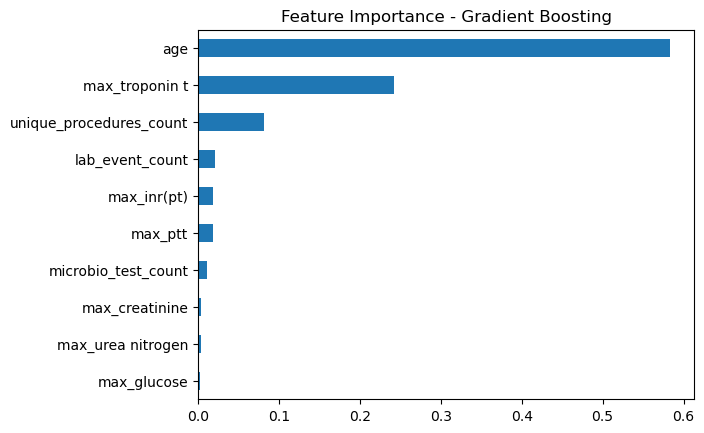

In [19]:
# Feature Importance for Gradient Boosting
feat_importances_gb = pd.Series(gb_clf.feature_importances_, index=X_train.columns)
feat_importances_gb.nlargest(10).plot(kind='barh', title='Feature Importance - Gradient Boosting')
plt.gca().invert_yaxis()
plt.show()

Gradient Boosting exhibits a much sharper focus. Age and Max Troponin alone account for approx. 85% of the total importance, while other metabolic markers (e.g., glucose, creatinine) drop to near-zero.

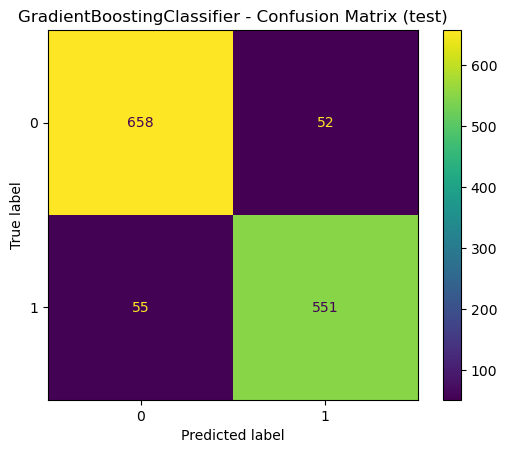


Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.92      0.93      0.92       710
    Ischemic (1)       0.91      0.91      0.91       606

        accuracy                           0.92      1316
       macro avg       0.92      0.92      0.92      1316
    weighted avg       0.92      0.92      0.92      1316



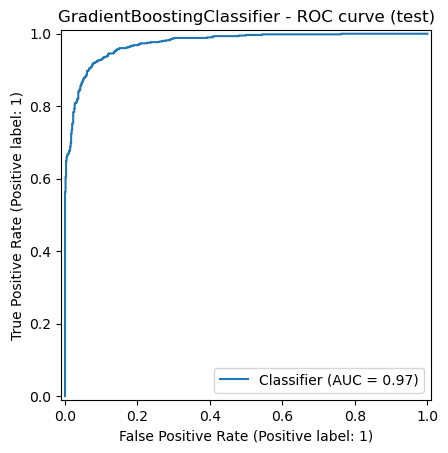

In [20]:
# Confusion matrix (test)
cm_rf = confusion_matrix(y_test, gb_y_test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=[0, 1])
disp.plot()
plt.title("GradientBoostingClassifier - Confusion Matrix (test)")
plt.show()

print("\nClassification report (test):")
print(classification_report(
    y_test, gb_y_test_pred,
    target_names=["Non-ischemic (0)", "Ischemic (1)"]
))

# ROC curve (test)
RocCurveDisplay.from_predictions(y_test, gb_y_test_proba)
plt.title("GradientBoostingClassifier - ROC curve (test)")
plt.show()


The confusion matrix shows a well-balanced classification performance.
Both false positives (52) and false negatives (55) are limited, indicating a good trade-off between sensitivity and specificity.
In particular, the number of missed ischemic patients is relatively low, which is desirable in a clinical setting.


## Random Forest

Random Forest is an ensemble method specifically designed for decision trees.
It combines the predictions made by multiple decision trees and outputs the class that is the mode of the class output by individual trees.

In [21]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
rf_clf = RandomForestClassifier(
    n_estimators=30, 
    criterion="gini", 
    max_features=3, 
    max_depth=4, 
    min_samples_split=2,
    min_samples_leaf=8, 
    bootstrap=True,  
    class_weight="balanced",
    random_state=42
)

In [23]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_dist = {
    "n_estimators": [30, 50, 100],
    "max_depth": [2, 4, 6, 8, None],
    "max_features": [2, 3, "sqrt"],
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(5, 20),
    "bootstrap": [True],
    "criterion": ["gini", "entropy"],
    "class_weight": ["balanced", None]
}


In [24]:
rf_base = RandomForestClassifier(random_state=42)

rf_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_dist,
    n_iter=30,
    scoring="balanced_accuracy",
    cv=5,
    n_jobs=-1,
    random_state=42
)

rf_search.fit(X_train, y_train)

print("Best parameters found:")
print(rf_search.best_params_)


Best parameters found:
{'bootstrap': True, 'class_weight': None, 'criterion': 'gini', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'min_samples_split': 3, 'n_estimators': 50}


In [25]:
rf_best = rf_search.best_estimator_

rf_best.fit(X_train, y_train)

rf_best_results, (rfb_y_train_pred, rfb_y_test_pred,
                  rfb_y_train_proba, rfb_y_test_proba) = evaluate_binary(
    rf_best, X_train, y_train, X_test, y_test
)

pd.Series(rf_best_results).sort_index()


test_accuracy              0.896657
test_balanced_accuracy     0.896007
test_f1                    0.887789
test_precision             0.887789
test_recall                0.887789
test_roc_auc               0.965193
train_accuracy             0.928292
train_balanced_accuracy    0.928410
train_f1                   0.922699
train_precision            0.915621
train_recall               0.929887
train_roc_auc              0.979954
dtype: float64

In [ ]:
# comparison with baseline RF and RF with tuned hyperparameters (RandomizedSearchCV)
rf_baseline = rf_clf 
rf_baseline.fit(X_train, y_train)

rf_base_results, _ = evaluate_binary(
    rf_baseline, X_train, y_train, X_test, y_test
)

comparison_rf = pd.DataFrame({
    "Baseline RF": rf_base_results,
    "Tuned RF": rf_best_results
})

comparison_rf.sort_index()


,Baseline RF,Tuned RF
test_accuracy,0.863982,0.896657
test_balanced_accuracy,0.864759,0.896007
test_f1,0.855529,0.887789
test_precision,0.837283,0.887789
test_recall,0.874587,0.887789
test_roc_auc,0.947276,0.965193
train_accuracy,0.886897,0.928292
train_balanced_accuracy,0.887925,0.928410
train_f1,0.879972,0.922699
train_precision,0.860041,0.915621


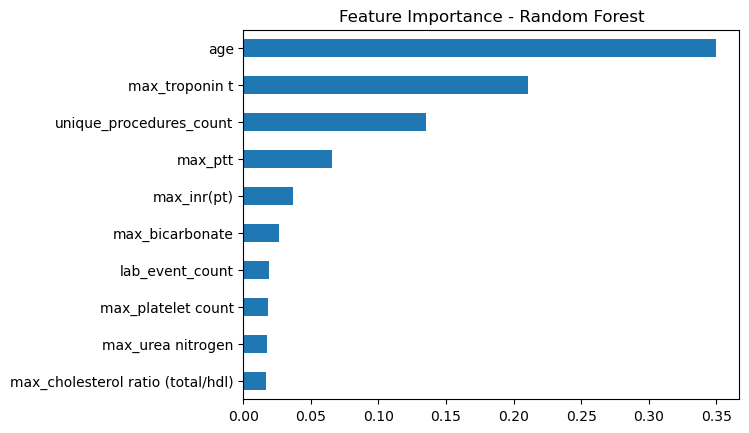

In [27]:
# Feature Importance for Random Forest
feat_importances = pd.Series(rf_best.feature_importances_, index=X_train.columns)
feat_importances.nlargest(10).plot(kind='barh', title='Feature Importance - Random Forest')
plt.gca().invert_yaxis()
plt.show()

The Feature Importance plot reveals that Age is the leading predictor for classifying ischemic vs non-ischemic patients. This is clinically consistent, as age is the primary demographic risk factor for cardiovascular disease prevalence.
Crucially, Max Troponin appears as the second most important feature. This confirms the model's validity, as it correctly identifies the specific biomarker for myocardial injury as a top discriminator.
The combination of demographic risk (Age), acute biomarkers (Troponin), and clinical complexity makes the Random Forest a robust and interpretable model."

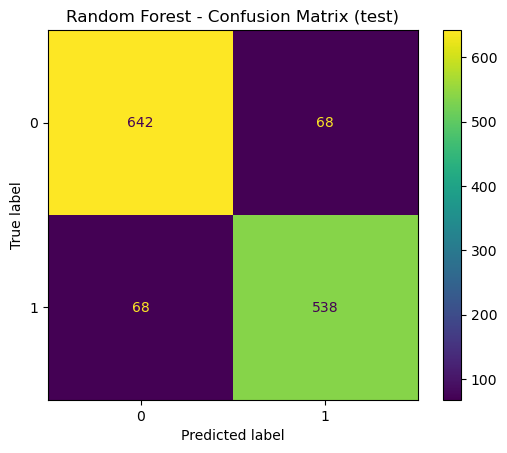


Classification report (test):
                  precision    recall  f1-score   support

Non-ischemic (0)       0.90      0.90      0.90       710
    Ischemic (1)       0.89      0.89      0.89       606

        accuracy                           0.90      1316
       macro avg       0.90      0.90      0.90      1316
    weighted avg       0.90      0.90      0.90      1316



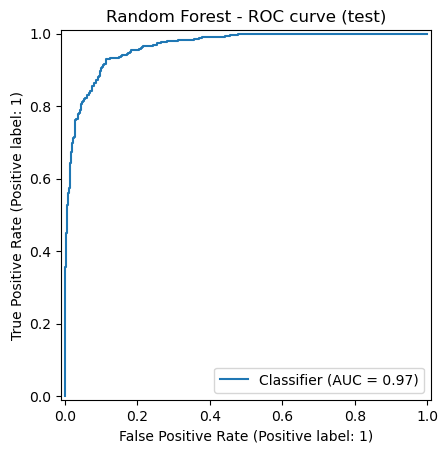

In [28]:
# Confusion matrix (test)
cm_rf = confusion_matrix(y_test, rfb_y_test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=[0, 1])
disp.plot()
plt.title("Random Forest - Confusion Matrix (test)")
plt.show()

print("\nClassification report (test):")
print(classification_report(
    y_test, rfb_y_test_pred,
    target_names=["Non-ischemic (0)", "Ischemic (1)"]
))

# ROC curve (test)
RocCurveDisplay.from_predictions(y_test, rfb_y_test_proba)
plt.title("Random Forest - ROC curve (test)")
plt.show()


The **ROC curve** represents the behavior of a classifier as the **decision threshold** applied to the predicted probability varies.

**X-axis – False Positive Rate (FPR)**  
Proportion of non-ischemic patients incorrectly classified as ischemic.

$\mathrm{FPR} = \dfrac{\mathrm{FP}}{\mathrm{FP} + \mathrm{TN}}$

**Y-axis – True Positive Rate (TPR) / Recall**  
Proportion of ischemic patients correctly identified.

$\mathrm{TPR} = \dfrac{\mathrm{TP}}{\mathrm{TP} + \mathrm{FN}}$


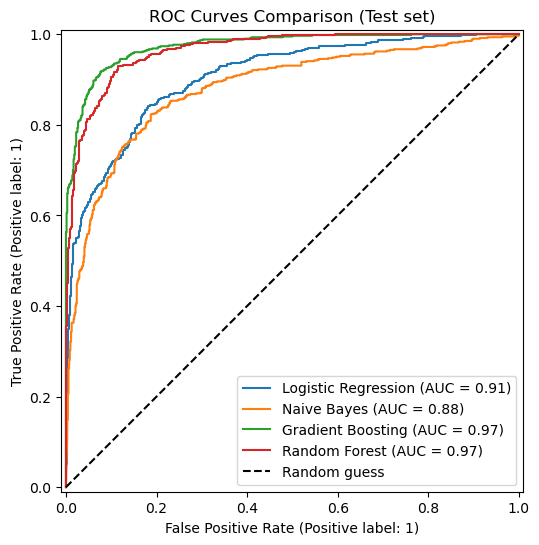

In [29]:

fig, ax = plt.subplots(figsize=(7, 6))

RocCurveDisplay.from_predictions(
    y_test, y_test_proba,
    name="Logistic Regression",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, nb_y_test_proba,
    name="Naive Bayes",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, gb_y_test_proba,
    name="Gradient Boosting",
    ax=ax
)

RocCurveDisplay.from_predictions(
    y_test, rfb_y_test_proba,
    name="Random Forest",
    ax=ax
)

ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC Curves Comparison (Test set)")
ax.legend()
plt.show()


Figure X compares the ROC curves of Logistic Regression, Naive Bayes, Gradient Boosting and Random Forest on the test set.
All models significantly outperform random guessing, confirming that the engineered features contain meaningful predictive information.

Random Forest and Gradient Boosting achieve the highest ROC-AUC values (both ≈ 0.97), indicating excellent discriminative ability across all decision thresholds.
Logistic Regression also performs remarkably well (AUC ≈ 0.91), despite its linear nature, suggesting that the decision boundary is largely linear in the feature space.
Naive Bayes shows lower performance, likely due to its strong conditional independence assumption, which is violated in this clinical dataset.


### Final Model Comparison (Test Set)

| Model                | Accuracy | Balanced Accuracy | Precision (1) | Recall (1) | F1-score (1) | ROC-AUC |
|---------------------|----------|-------------------|---------------|------------|--------------|---------|
| Logistic Regression | 0.82     | 0.82              | 0.82          | 0.78       | 0.80         | 0.91    |
| Naive Bayes         | 0.79     | 0.78              | 0.88          | 0.64       | 0.74         | 0.88    |
| Gradient Boosting   | 0.92     | 0.92              | 0.91          | 0.91       | 0.91         | 0.97    |
| Random Forest       | 0.90     | 0.90              | 0.89          | 0.89       | 0.89         | 0.97    |

The comparison highlights clear differences among the evaluated models.

Logistic Regression provides a strong and well-balanced baseline, with stable performance across all metrics and good generalization.
Its high ROC-AUC indicates effective ranking capability, while its linear structure ensures interpretability, which is desirable in clinical decision support systems.

Naive Bayes achieves high precision but significantly lower recall for the ischemic class, reflecting its strong conditional independence assumption and a tendency to miss positive cases.
This behavior may be problematic in a clinical context, where false negatives are critical.

Gradient Boosting and Random Forest achieve the best overall performance.
Gradient Boosting provides excellent discriminative ability and a very balanced precision–recall trade-off, benefiting from its ability to capture non-linear feature interactions while maintaining controlled model complexity.
Random Forest achieves comparable ROC-AUC and slightly higher robustness, leveraging variance reduction through ensemble averaging.

Overall, while Random Forest and Gradient Boosting deliver the highest predictive performance, Logistic Regression remains an attractive alternative due to its interpretability and stability, making it a suitable baseline model in clinical settings.
